агент → трейсы в Langfuse → золотой набор → прогоны → оценка

In [1]:
import json, os, re, subprocess, sys, textwrap, time
import duckdb, pandas as pd

if os.path.exists(".env"):                                   
    os.environ.update(dict(line.strip().split("=", 1) for line in open(".env") if "=" in line))

from langfuse import Langfuse, observe, propagate_attributes
from langfuse.openai import OpenAI                            

AGENT_MODEL = "mistralai/ministral-8b-2512"                   # слабая модель под тестом: 8B, умеет function calling, 256k контекст
JUDGE_MODEL = "anthropic/claude-sonnet-5"                      # средняя модель судит
DB, MAX_STEPS, ROW_LIMIT, PY_TIMEOUT = "data/sber.duckdb", 12, 50, 30
RUN_ID = time.strftime("run-%Y%m%d-%H%M%S")                   # session_id в Langfuse

langfuse = Langfuse()                                          
client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.environ["OPENROUTER_API_KEY"], max_retries=3)
print("langfuse:", langfuse.auth_check(), "| run:", RUN_ID)

langfuse: True | run: run-20261105-144555


## 1. Простой агент

Данные: сделки с квартирами в Москве 2011–2015 (Kaggle «Sberbank Russian Housing Market») в DuckDB, три таблицы:
`deals` (сделки), `raion` (атрибуты района), `macro` (дневные макропоказатели). 
Данные грязные

In [2]:
if not os.path.exists(DB):                                    # raw csv -> три таблицы, без чистки
    b = duckdb.connect(DB)
    b.execute("""
    create table deals as select id, timestamp::date as date, price_doc as price, full_sq, life_sq, floor, max_floor,
        num_room, kitch_sq, build_year, state, material, product_type, sub_area, kremlin_km, metro_min_walk, metro_km_avto, ecology
        from read_csv_auto('data/raw/train.csv', nullstr='NA');
    create table raion as select distinct sub_area, area_m, raion_popul, green_zone_part, indust_part,
        school_education_centers_top_20_raion as top20_schools, university_top_20_raion as top20_unis,
        shopping_centers_raion, thermal_power_plant_raion, detention_facility_raion, nuclear_reactor_raion
        from read_csv_auto('data/raw/train.csv', nullstr='NA');
    create table macro as select timestamp::date as date, oil_urals, usdrub, eurrub, cpi, ppi, mortgage_rate,
        mortgage_value, salary, unemployment, rent_price_2room_eco, rent_price_1room_eco
        from read_csv_auto('data/raw/macro.csv', nullstr='NA');""")
    b.close()

con = duckdb.connect(DB, read_only=True)
for table in ["deals", "raion", "macro"]:
    print(table, con.sql(f"select count(*) from {table}").fetchone()[0], "rows")
con.sql("select * from deals").df().tail()


deals 30471 rows
raion 146 rows
macro 2484 rows


,id,date,price,full_sq,life_sq,floor,max_floor,num_room,kitch_sq,build_year,state,material,product_type,sub_area,kremlin_km,metro_min_walk,metro_km_avto,ecology
30466,30469,2015-06-30,7400000,44,27,7,9,2,6,1975,3,1,Investment,Otradnoe,12.599292,8.158093,0.659002,good
30467,30470,2015-06-30,25000000,86,59,3,9,4,10,1935,3,2,Investment,Tverskoe,3.269284,9.374609,0.781217,poor
30468,30471,2015-06-30,6970959,45,<NA>,10,20,1,1,<NA>,1,1,OwnerOccupier,Poselenie Vnukovskoe,21.905792,20.666800,1.722233,no data
30469,30472,2015-06-30,13500000,64,32,5,15,2,11,2003,2,1,Investment,Obruchevskoe,13.622569,24.567748,2.047312,satisfactory
30470,30473,2015-06-30,5600000,43,28,1,9,2,6,1968,2,1,Investment,Novogireevo,11.812614,5.455795,0.454650,poor


In [3]:
con.sql("select * from raion limit 5").df().tail()

,sub_area,area_m,raion_popul,green_zone_part,indust_part,top20_schools,top20_unis,shopping_centers_raion,thermal_power_plant_raion,detention_facility_raion,nuclear_reactor_raion
0,Moskvorech'e-Saburovo,10046857.44,76156,0.071056,0.246032,0,1,3,False,False,True
1,Veshnjaki,10518366.87,118945,0.334905,0.012339,0,0,4,False,False,False
2,Danilovskoe,12495435.25,91100,0.027651,0.341072,0,0,11,True,False,False
3,Nizhegorodskoe,7506452.02,43795,0.007670,0.486246,0,0,6,True,False,False
4,Lianozovo,5646405.14,79576,0.258663,0.101872,0,0,3,False,False,False


In [4]:
con.sql("select * from macro limit 500").df().tail()

,date,oil_urals,usdrub,eurrub,cpi,ppi,mortgage_rate,mortgage_value,salary,unemployment,rent_price_2room_eco,rent_price_1room_eco
495,2011-05-11,111.14,27.7981,39.5247,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94
496,2011-05-12,111.14,27.9392,39.8623,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94
497,2011-05-13,111.14,28.1475,39.5707,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94
498,2011-05-14,111.14,28.1475,39.5707,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94
499,2011-05-15,111.14,28.1475,39.5707,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94


Три инструмента. `run_python` — вся песочница курса: отдельный процесс, таймаут, база только на чтение. Без docker.
`@observe(as_type="tool")` — единственное, что добавляет Langfuse: каждый вызов инструмента станет узлом в трейсе.

In [5]:
@observe(as_type="tool")
def run_sql(query: str) -> str:
    """read-only DuckDB, не больше ROW_LIMIT строк"""
    try:
        return con.sql(query).limit(ROW_LIMIT).df().to_markdown(index=False)
    except Exception as e:
        return f"ERROR: {e}"

PREAMBLE = "import duckdb, pandas as pd, numpy as np\ncon = duckdb.connect('sber.duckdb', read_only=True)\n"

@observe(as_type="tool")
def run_python(code: str) -> str:
    """отдельный процесс + таймаут + read-only база"""
    try:
        p = subprocess.run([sys.executable, "-c", PREAMBLE + code], cwd="data", capture_output=True, text=True, timeout=PY_TIMEOUT)
        return ((f"ERROR:\n{p.stderr}\n" if p.returncode else "") + p.stdout)[:4000] or "(no output — use print())"
    except subprocess.TimeoutExpired:
        return f"ERROR: timeout {PY_TIMEOUT}s"

def call(name, args):                                         
    try: return {"run_sql": run_sql, "run_python": run_python}[name](**args)
    except Exception as e: return f"ERROR: {e}"

def loads(s):
    try: return json.loads(s or "{}")
    except json.JSONDecodeError: return {}

def tool(name, desc, props):
    return {"type": "function", "function": {"name": name, "description": desc,
            "parameters": {"type": "object", "properties": props, "required": list(props)}}}

TOOLS = [tool("run_sql", "SQL (DuckDB, read-only) к таблицам deals, raion, macro.", {"query": {"type": "string"}}),
         tool("run_python", "Python; уже есть con (duckdb), pd, np. Результат через print().", {"code": {"type": "string"}}),
         tool("final_answer", "Итоговый ответ на вопрос пользователя.",
              {"answer": {"type": "string"}, "confidence": {"type": "number"}})]

Системный промпт

In [6]:
def schema():
    return "\n".join(f"{t}: " + ", ".join(f"{c} {ty}" for c, ty in con.sql(f"select column_name, column_type from (describe {t})").fetchall())
                     for t in ["deals", "raion", "macro"])

SYSTEM = f"""Ты аналитик данных. Отвечаешь на вопросы о сделках с квартирами в Москве (2011–2015),
исследуя базу DuckDB инструментами run_sql и run_python.

Таблицы (deals - сделки, raion - атрибуты района по sub_area, macro - дневные макропоказатели по date):
{schema()}

Правила:
1. Перед расчётом сделай select с примером строк.
2. Для сложных или вложенных запросов используй python 
3. Всегда завершай вызовом final_answer."""
print(SYSTEM)

Ты аналитик данных. Отвечаешь на вопросы о сделках с квартирами в Москве (2011–2015),
исследуя базу DuckDB инструментами run_sql и run_python.

Таблицы (deals - сделки, raion - атрибуты района по sub_area, macro - дневные макропоказатели по date):
deals: id BIGINT, date DATE, price BIGINT, full_sq BIGINT, life_sq BIGINT, floor BIGINT, max_floor BIGINT, num_room BIGINT, kitch_sq BIGINT, build_year BIGINT, state BIGINT, material BIGINT, product_type VARCHAR, sub_area VARCHAR, kremlin_km DOUBLE, metro_min_walk DOUBLE, metro_km_avto DOUBLE, ecology VARCHAR
raion: sub_area VARCHAR, area_m DOUBLE, raion_popul BIGINT, green_zone_part DOUBLE, indust_part DOUBLE, top20_schools BIGINT, top20_unis BIGINT, shopping_centers_raion BIGINT, thermal_power_plant_raion BOOLEAN, detention_facility_raion BOOLEAN, nuclear_reactor_raion BOOLEAN
macro: date DATE, oil_urals DOUBLE, usdrub DOUBLE, eurrub DOUBLE, cpi DOUBLE, ppi DOUBLE, mortgage_rate DOUBLE, mortgage_value BIGINT, salary DOUBLE, unemployment DOU

Сам агент — один цикл: модель → инструмент → результат в историю → повторить, не больше `MAX_STEPS` раз.
`@observe(as_type="agent")` делает из вызова `run()` трейс; генерации и инструменты внутри вкладываются сами.
`propagate_attributes` вешает на трейс `session_id` прогона и теги — по ним потом найдём трейсы для оценки.

In [7]:
NUDGE = {"role": "user", "content": "Это текст, а не вызов инструмента. Вызови run_sql / run_python или final_answer."}

@observe(as_type="agent", name="sber-agent", capture_input=False, capture_output=False)
def run(prompt, tags=()):
    """Локальный trace — чтобы напечатать здесь. Настоящий уходит в Langfuse сам."""
    langfuse.update_current_span(input=prompt)                              # вход трейса 
    with propagate_attributes(session_id=RUN_ID, tags=list(tags)):
        msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}]
        trace, out = [], {"answer": None, "status": "max_steps", "trace_id": langfuse.get_current_trace_id()}
        for step in range(MAX_STEPS):
            r = client.chat.completions.create(model=AGENT_MODEL, messages=msgs, tools=TOOLS, max_tokens=4096, name="agent-step",
                                               extra_body={"usage": {"include": True}, "provider": {"require_parameters": True}})
            m = r.choices[0].message
            if not m.tool_calls:                                            # толкаем вручную если модель не дернула тулы
                trace.append({"step": step, "text": m.content})
                msgs += [{"role": "assistant", "content": m.content}, NUDGE]
                continue
            tc = m.tool_calls[0]
            args = loads(tc.function.arguments)
            trace.append({"step": step, "tool": tc.function.name, "args": args})
            if tc.function.name == "final_answer":
                out.update(answer=str(args.get("answer")), status="ok")
                break
            result = call(tc.function.name, args)
            trace.append({"step": step, "result": result})
            msgs += [{"role": "assistant", "content": m.content, "tool_calls": [tc.model_dump()]},
                     {"role": "tool", "tool_call_id": tc.id, "content": result}]
        out.update(steps=step + 1, trace=trace)
        langfuse.update_current_span(output=out["answer"])                  # выход трейса
        return out

Один тестовый прогон и трейс, напечатанный прямо здесь.

In [8]:
def show_trace(trace):
    for r in trace:
        if "result" in r: print(textwrap.indent(r["result"][:500], "      │ "))
        elif "tool" in r: print(f"\n[{r['step']}] {r['tool']}\n" + textwrap.indent("\n".join(map(str, r["args"].values())), "      "))
        else:             print(f"\n[{r['step']}] текст вместо вызова: {r['text']}")

res = run("Сколько всего сделок в таблице deals?", tags=["demo"])
show_trace(res["trace"])
print("\nanswer:", res["answer"], "| status:", res["status"], "| trace_id:", res["trace_id"])


[0] run_sql
      SELECT COUNT(*) AS total_deals FROM deals;
      │ |   total_deals |
      │ |--------------:|
      │ |         30471 |

[1] final_answer
      В таблице deals всего 30 471 сделка.
      1

answer: В таблице deals всего 30 471 сделка. | status: ok | trace_id: f6fe407ac686f66973411bc63e96fc50


## 2. Langfuse

Пока мы печатали свой список шагов, SDK отправил в Langfuse настоящий трейс: корень `sber-agent`, внутри — `generation` на каждый
вызов модели (модель, токены) и `tool` на каждый инструмент (аргументы и результат). В Langfuse v4 трейс — это набор
observations с одним `traceId`; достаём их одним запросом. Ингест асинхронный, поэтому при чтении немного ждём.

In [9]:
BASE, FIELDS = os.environ["LANGFUSE_BASE_URL"], "core,basic,io,model,usage,trace_context"

def trace_rows(trace_id, wait=90):
    """Все observations трейса из Langfuse"""
    langfuse.flush()
    for _ in range(wait // 3):
        rows = langfuse.api.observations.get_many(trace_id=trace_id, fields=FIELDS, limit=100).data
        if any(o.is_root_observation for o in rows): return sorted(rows, key=lambda o: o.start_time)
        time.sleep(3)
    raise TimeoutError(f"trace {trace_id} not in Langfuse after {wait}s")

rows = trace_rows(res["trace_id"])
root = next(o for o in rows if o.is_root_observation)
print(f"{BASE}/project/sber-eval/traces/{res['trace_id']}\n")
print("input:  ", root.input, "\noutput: ", root.output, "\nsession:", root.session_id, "| tags:", root.tags, "\n")
for o in rows:
    tokens = o.usage_details.get("total", "") if o.usage_details else ""
    print(f"{o.type:10} {o.name:12} {tokens!s:>5}  in={str(o.input)[:60]!r:64} out={str(o.output)[:60]!r}")

http://localhost:3000/project/sber-eval/traces/f6fe407ac686f66973411bc63e96fc50

input:   Сколько всего сделок в таблице deals? 
output:  В таблице deals всего 30 471 сделка. 
session: run-20261105-144555 | tags: ['demo'] 

AGENT      sber-agent          in='Сколько всего сделок в таблице deals?'                          out='В таблице deals всего 30 471 сделка.'
GENERATION agent-step     646  in='{"tools": [{"type": "function", "function": {"name": "run_sq'   out='{"role": "assistant", "tool_calls": [{"id": "za5SXOztP", "fu'
TOOL       run_sql             in='{"args": [], "kwargs": {"query": "SELECT COUNT(*) AS total_d'   out='|   total_deals |\n|--------------:|\n|         30471 |'
GENERATION agent-step     745  in='{"tools": [{"type": "function", "function": {"name": "run_sq'   out='{"role": "assistant", "tool_calls": [{"id": "k1VdxXykz", "fu'


## 3. Ground truth

GT это текст, описывающий какое поведение от агента ожидалось, как должен выглядеть ответ и какие данные в нём должны быть.
Два простых кейса (контрольная группа — слабая модель обязана их проходить) и три сложных: join с макро, статистика, разведка грязных данных.
GT пишет человек или сильная модель

In [10]:
CASES = [
 {"id": "easy-1", "prompt": "Сколько сделок было заключено в 2014 году?",
  "gold": "Посчитать число строк deals с фильтром по году даты сделки. Ответ — одно целое число порядка 13–14 тысяч "
          "(около 13.7 тыс.) с пояснением, что это сделки за 2014 год. Оговорки не нужны: вопрос однозначный."},
 {"id": "easy-2", "prompt": "Топ-5 районов (sub_area) по числу сделок.",
  "gold": "group by sub_area, сортировка по убыванию, первые пять. Ответ — пять названий как в данных (латиницей) с числом сделок "
          "у каждого: Poselenie Sosenskoe, Nekrasovka, Poselenie Vnukovskoe, Poselenie Moskovskij, Poselenie Voskresenskoe. "
          "Замечание, что всё это Новая Москва (массовые новостройки), — плюс, не обязательно."},
 {"id": "hard-1", "prompt": "Медианная цена за м² в Хамовниках (sub_area = 'Hamovniki') в 2014 году, в долларах по курсу usdrub на дату сделки.",
  "gold": "join deals с macro по дате сделки; цена / full_sq / usdrub этого дня; медиана по сделкам 2014 года в Hamovniki, строки "
          "с full_sq = 0 исключить. Ответ — одно число около 7 тысяч $/м² с единицами и числом сделок (несколько десятков). "
          "Средний курс за год вместо дневного — методическая ошибка."},
 {"id": "hard-2", "prompt": "Коэффициент корреляции Пирсона между ценой за м² и kremlin_km для сделок Investment с ценой > 2 млн руб. и full_sq > 0.",
  "gold": "Фильтры product_type = 'Investment', price > 2 000 000, full_sq > 0; корреляция Пирсона между price/full_sq и kremlin_km "
          "(corr() в SQL или pandas). Ответ — отрицательное число около −0.3 (дальше от Кремля — дешевле) с указанием фильтров "
          "и числа сделок. Положительный знак или корреляция с ценой, а не с ценой за м², — ошибка. "
          "Сравнение с OwnerOccupier (там связь почти нулевая) — плюс."},
 {"id": "hard-3", "prompt": "В данных есть сделки с ценой-заглушкой (около 10% сделок). Найди их, обоснуй выбранный порог и сообщи медианную цену за м² с ними и без них.",
  "gold": "Разведка. Посмотреть распределение цен и увидеть пики ровно на 1 и 2 млн руб. (по ~750 сделок), почти все — Investment. "
          "Порог может быть любым обоснованным (цена ≤ 2 млн, ≤ 3 млн, цена за м² ниже ~30 тыс.), но названным и объяснённым. "
          "Ответ — число или доля найденных сделок, медиана цены за м² со всеми (~135 тыс. руб.) и без заглушек (~140–143 тыс. руб.), "
          "и честное замечание, что порог — допущение."},
]
pd.DataFrame(CASES)[["id", "prompt"]]

,id,prompt
0,easy-1,Сколько сделок было заключено в 2014 году?
1,easy-2,Топ-5 районов (sub_area) по числу сделок.
2,hard-1,Медианная цена за м² в Хамовниках (sub_area = ...
3,hard-2,Коэффициент корреляции Пирсона между ценой за ...
4,hard-3,В данных есть сделки с ценой-заглушкой (около ...


## 4. Прогоны: агент × 5 кейсов → Langfuse

Здесь агент только работает. Никаких оценок: от прогона остаются трейсы в Langfuse с `session_id = RUN_ID` и тегом кейса.

In [11]:
for case in CASES:
    res = run(case["prompt"], tags=[case["id"]])
    print(f"{case['id']:7} {res['status']:9} steps={res['steps']:>2} answer={str(res['answer'])[:80]!r}")
langfuse.flush()
print(f"\n{os.environ['LANGFUSE_BASE_URL']}/project/sber-eval/sessions/{RUN_ID}")

easy-1  ok        steps= 2 answer='В 2014 году было заключено **13 662 сделок** с квартирами в Москве.'


easy-2  ok        steps= 2 answer='Топ-5 районов по числу сделок с квартирами в Москве (2011–2015): 1) Poselenie So'


hard-1  max_steps steps=12 answer='None'


hard-2  ok        steps= 7 answer='Коэффициент корреляции Пирсона между ценой за квадратный метр и расстоянием до К'


hard-3  max_steps steps=12 answer='None'

http://localhost:3000/project/sber-eval/sessions/run-20261105-144555


## 5. Оценка: трейсы из Langfuse → судья → скор обратно в Langfuse → график

Judge забирает все observations сессии, по тегу узнаёт кейс, читает
финальный ответ и вызовы инструментов, сравнивает с эталонным описанием по рубрике
correctness 0–2 / method 0–1 / honesty 0–1 и пишет скор к трейсу. Скоры видны в UI и читаются обратно через `scores_v3`.

In [12]:
RUBRIC = """Ты проверяющий. Даны вопрос, эталонное описание (что агент должен был сделать и как должен выглядеть ответ),
итоговый ответ агента и его трейс (вызовы инструментов и результаты).
correctness — ответ содержит то, чего требует эталон (2), частично (1), нет (0).
method — по трейсу видно, что агент реально сделал описанное в эталоне (1), а не выдумал (0).
reason — одна-две фразы, почему такие оценки."""

SCHEMA = {"type": "object", "additionalProperties": False,
 "required": ["correctness", "method", "reason"],
 "properties": {"correctness": {"type": "integer", "enum": [0, 1, 2]},
 "method": {"type": "integer", "enum": [0, 1]},
 "reason": {"type": "string"},
}}

def trace_text(rows):
    """Observations трейса -> текст для судьи: ответы модели и вызовы инструментов по порядку."""
    lines = []
    for o in rows:
        if o.type == "GENERATION": lines.append(f"model -> {o.output}")
        if o.type == "TOOL":       lines.append(f"{o.name}({o.input}) -> {o.output}")
    return "\n".join(lines)

@observe(as_type="evaluator", name="judge")
def judge(case, answer, rows):
    user = f"Вопрос: {case['prompt']}\n\nЭталон: {case['gold']}\n\nОтвет агента: {answer}\n\nТрейс:\n{trace_text(rows)}"
    r = client.chat.completions.create(model=JUDGE_MODEL, messages=[{"role": "system", "content": RUBRIC}, {"role": "user", "content": user}],
                                       response_format={"type": "json_schema", "json_schema": {"name": "verdict", "strict": True, "schema": SCHEMA}})
    v = json.loads(r.choices[0].message.content)                            # форму гарантирует API, парсить нечего
    return {"score": (v["correctness"] + v["method"]) / 3, **v}                # максимум 2 + 1 = 3

In [13]:
def session_rows(run_id, n_traces, wait=90):
    """Все observations прогона по session_id. Ждём, пока доедут корни всех n трейсов."""
    for _ in range(wait // 3):
        rows = langfuse.api.observations.get_many(session_id=run_id, fields=FIELDS, limit=500).data
        if sum(o.is_root_observation for o in rows) >= n_traces: return rows
        time.sleep(3)
    return rows

rows = session_rows(RUN_ID, len(CASES) + 1)                                  # +1: demo-трейс из шага 1
by_case = {c["id"]: c for c in CASES}
results = []
for root in [o for o in rows if o.is_root_observation]:
    case = next((by_case[tag] for tag in root.tags if tag in by_case), None)
    if case is None: continue                                                # demo-трейс без кейса
    steps = sorted([o for o in rows if o.trace_id == root.trace_id], key=lambda o: o.start_time)
    v = judge(case, root.output, steps)
    langfuse.create_score(trace_id=root.trace_id, name="judge", value=v["score"], comment=v["reason"])   # скор — рядом с трейсом
    results.append({"case": case["id"], **v, "trace_id": root.trace_id})
    print(f"{case['id']:7} score={v['score']:.2f}  {v['reason'][:100]}")
langfuse.flush()
df = pd.DataFrame(results).sort_values("case").reset_index(drop=True)
df[["case", "score", "correctness", "method", "reason"]]

hard-3  score=0.00  Финальный ответ агента отсутствует (None), в трейсе — серия неудачных попыток подключиться к duckdb 


hard-2  score=0.33  Агент не смог подключиться к полной таблице deals (SHOW TABLES вернул пусто, запросы к ней падали) и


hard-1  score=0.00  Агент так и не смог получить результат из-за ошибок с подключением к БД в run_python (таблицы deals 


easy-2  score=1.00  Ответ полностью совпадает с эталоном (названия и числа сделок), запрос в трейсе корректно реализует 


easy-1  score=1.00  Агент выполнил SQL-запрос с фильтром по году даты сделки и получил 13662, что соответствует эталонно


,case,score,correctness,method,reason
0,easy-1,1.000000,2,1,Агент выполнил SQL-запрос с фильтром по году д...
1,easy-2,1.000000,2,1,Ответ полностью совпадает с эталоном (названия...
2,hard-1,0.000000,0,0,Агент так и не смог получить результат из-за о...
3,hard-2,0.333333,1,0,Агент не смог подключиться к полной таблице de...
4,hard-3,0.000000,0,0,"Финальный ответ агента отсутствует (None), в т..."


kind
easy    1.00
hard    0.11
Name: score, dtype: float64

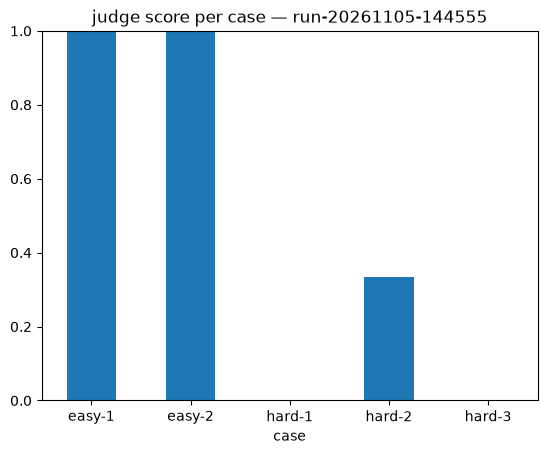

In [14]:
ax = df.set_index("case").score.plot.bar(ylim=(0, 1), rot=0, title=f"judge score per case — {RUN_ID}")
df.assign(kind=df.case.str.split("-").str[0]).groupby("kind").score.mean().round(2)

In [ ]:
 id | date | price | full_sq | life_sq | floor | max_floor | num_room | kitch_sq | build_year | state | material | product_type | sub_area | kremlin_km | metro_min_walk | metro_km_avto | ecology |\n|------:|:--------------------|--------:|----------:|----------:|--------:|------------:|-----------:|-----------:|-------------:|:--------|-----------:|:---------------|:------------|-------------:|-----------------:|----------------:|:----------|\n| 13573 | 2014-01-09 00:00:00 | 5150000 | 38 | 18 | 1 | 14 | 1 | 9 | 1971 | <NA> | 1 | Investment | Dmitrovskoe | 14.8564 | 27.0842 | 2.56322 | poor |\n| 13574 | 2014-01-09 00:00:00 | 5980000 | 41 | 17 | 14 | 16 | 1 | 10 | 1978 | 3 | 1 | Investment | Savelovskoe | 5.3237 | 13.7192 | 0.705344 | poor |\n| 13575 | 2014-01-09 00:00:00 | 4600000 | 41 | 20 | 11 | 14 | 1 | 8 | 1989 | 2 | 1 | Investment | Krjukovo | 38.9889 | 276.454 | 23.2419 | no data |\n| 13576 | 2014-01-09 00:00:00 | 5650000 | 38 | 19 | 6 | 17 | 1 | 8 | 1986 | 2 | 1 | Investment | Brateevo 

In [ ]:
[
    {"district": "Dmitrovskoe", "price": 5150000, "full_sq": 38, "life_sq": 18, "floor": 1, "max_floor": 14, "num_room": 1, "kitch_sq": 9, "build_year": 1971, "state": "NA", "material": 1, "product_type": "Investment", "sub_area": "Dmitrovskoe", "kremlin_km": 14.8564, "metro_min_walk": 27.0842, "metro_km_avto": 2.56322, "ecology": "poor"},
    {"district": "Savelovskoe", "price": 5980000, "full_sq": 41, "life_sq": 17, "floor": 14, "max_floor": 16, "num_room": 1, "kitch_sq": 10, "build_year": 1978, "state": 3, "material": 1, "product_type": "Investment", "sub_area": "Savelovskoe", "kremlin_km": 5.3237, "metro_min_walk": 13.7192, "metro_km_avto": 0.705344, "ecology": "poor"},
]

Что смотреть в Langfuse (http://localhost:3000): **Tracing → Sessions** — сессия `RUN_ID`, все прогоны рядом;
**Traces** — фильтр по тегу кейса, дерево agent → generation / tool, вход и выход каждого шага;
**Scores** — колонка `judge` у каждого трейса с комментарием судьи. Повторный запуск шага 5 добавит новые скоры к тем же трейсам.